# What does $\delta$ do to a power weight?

For $w_\delta(x)=x^\delta$ on $\mathbb R_+$, animate $\delta$ from $-0.45$ to $0.45$ at $p=2$. The horizontal axis is logarithmic and both axis limits stay fixed. The three review stills use $\delta=-0.4,0,0.4$.

In [1]:
# ============================================================
# USER PARAMETERS
# ============================================================
# MATHEMATICAL PARAMETERS
p = 2.0
DELTA_START = -0.45
DELTA_END = 0.45
# ANIMATION PARAMETERS
FPS = 24
SPEED_FACTOR = 1.0
BASE_DURATION = 6.0  # effective duration = BASE_DURATION / SPEED_FACTOR

## Mathematical checkpoint

At $p=2$, the admissible interval is $-1/2<\delta<1/2$. Every weight equals $1$ at $x=1$. For $x<1$, increasing $\delta$ decreases $x^\delta$; for $x>1$, it increases $x^\delta$. A log $x$ axis makes the two regimes visible without moving the camera.

In [2]:
from pathlib import Path
import sys
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
elif not (project_dir / "src" / "geometry.py").exists():
    project_dir = project_dir / "karlovich_2025_cusps"
if not (project_dir / "src" / "geometry.py").exists():
    raise FileNotFoundError("Run this notebook from its project folder or the repository root.")
sys.path.insert(0, str(project_dir / "src"))
output_dir = project_dir / "outputs"

from render_power_weights import render_power_weights
assert p > 1 and -1/p < DELTA_START <= -0.4 < 0.4 <= DELTA_END < 1-1/p
assert FPS > 0 and SPEED_FACTOR > 0 and BASE_DURATION > 0
for d in (-0.4, 0.0, 0.4):
    print(f"delta={d:+.1f}: w(0.01)={0.01**d:.3f}, w(1)={1.0**d:.3f}, w(100)={100.0**d:.3f}")

delta=-0.4: w(0.01)=6.310, w(1)=1.000, w(100)=0.158
delta=+0.0: w(0.01)=1.000, w(1)=1.000, w(100)=1.000
delta=+0.4: w(0.01)=0.158, w(1)=1.000, w(100)=6.310


## Animate the parameter

The moving label reports the current $\delta$. The exported static PDF overlays the three reference values; the GIF/MP4 sweep continuously between the endpoints.

gif: outputs/power_weights_v1.gif
mp4: outputs/power_weights_v1.mp4
png: outputs/power_weights_v1.png
pdf: outputs/power_weights_v1_static.pdf
144 frames; 6.00 seconds


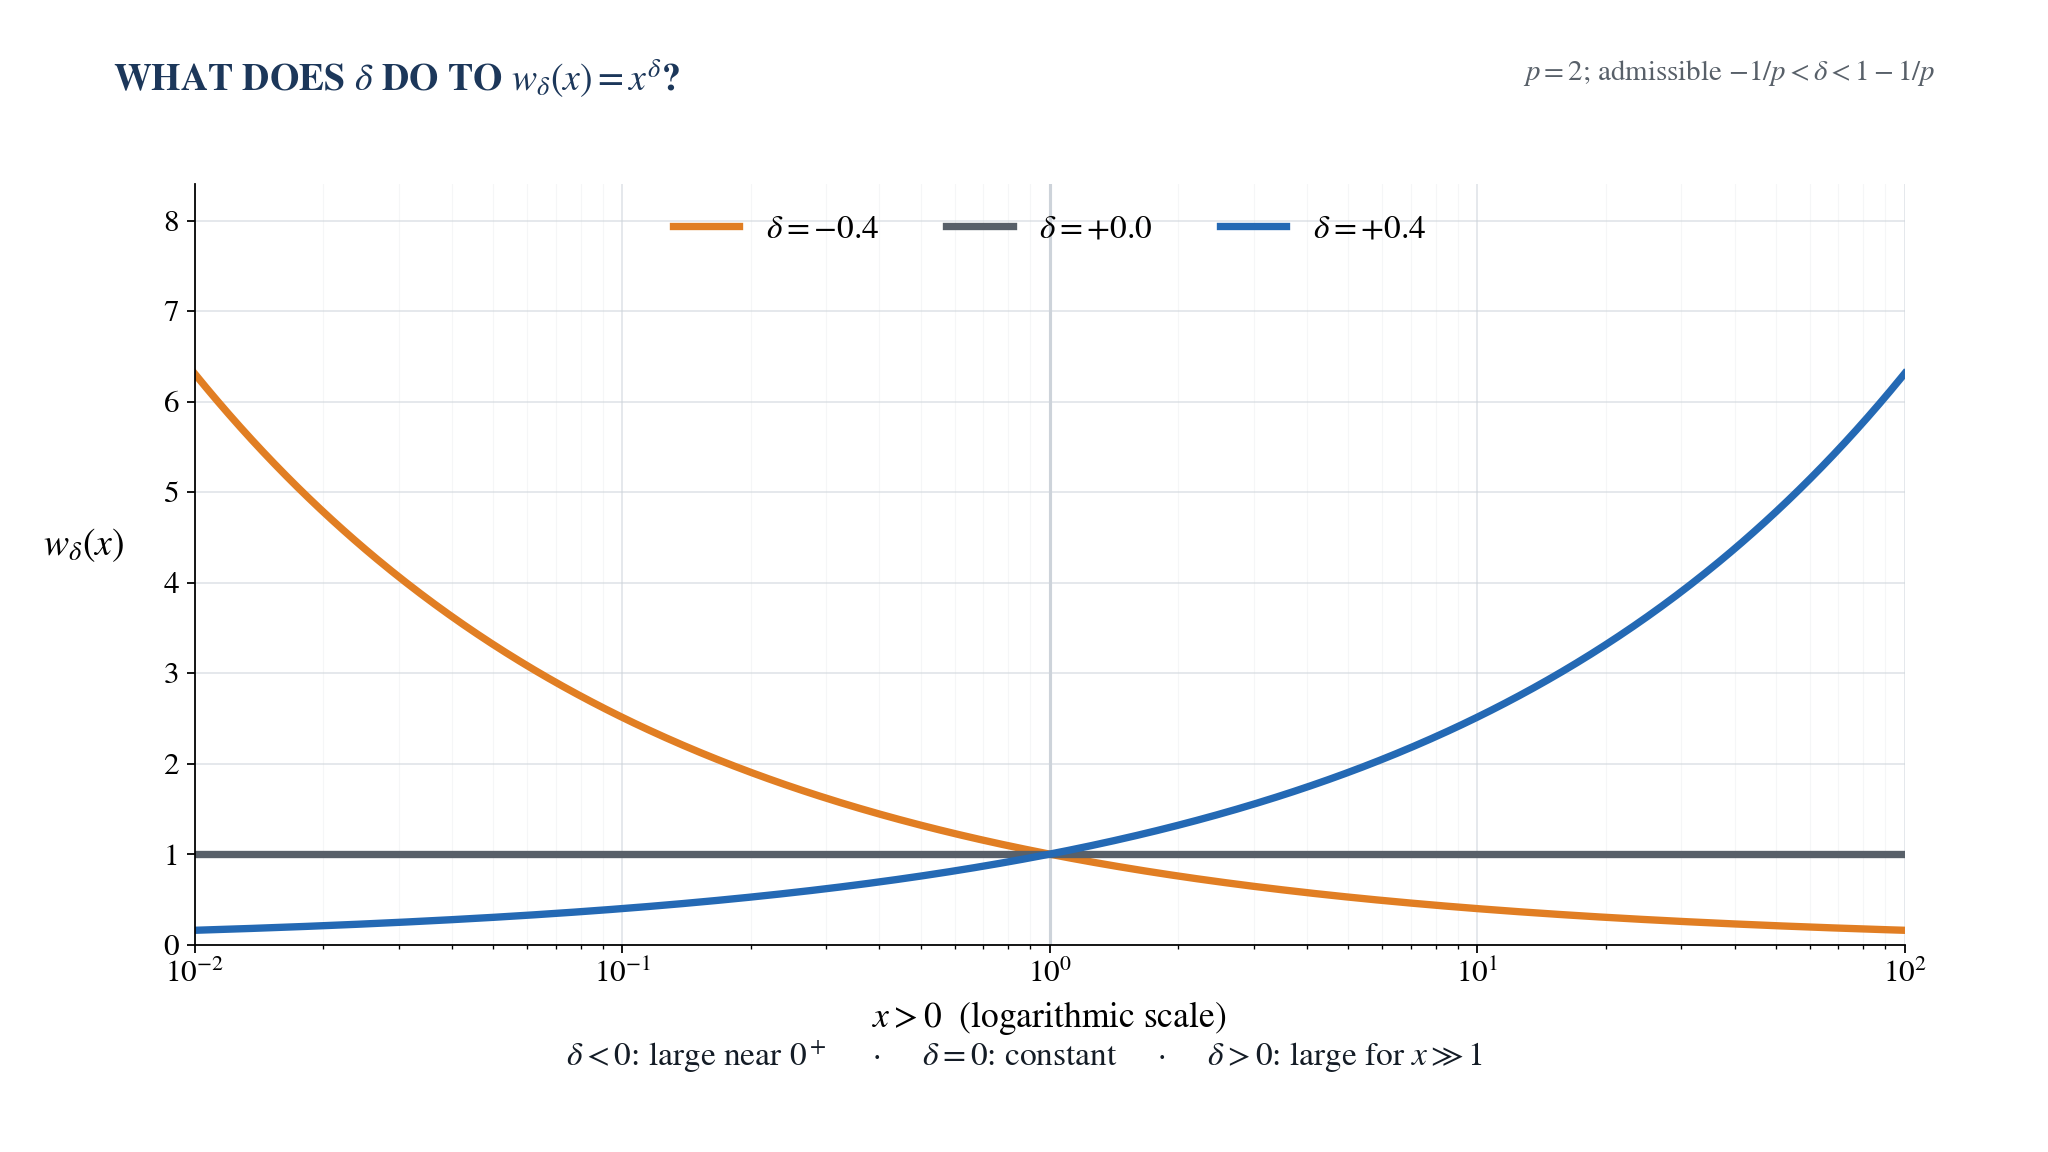

In [3]:
from IPython.display import Image, Markdown, display
assets = render_power_weights(output_dir, p=p, fps=FPS,
                              duration=BASE_DURATION, speed_factor=SPEED_FACTOR,
                              delta_start=DELTA_START, delta_end=DELTA_END)
for key in ("gif", "mp4", "png", "pdf"):
    print(f"{key}: {assets[key].relative_to(project_dir)}")
print(f"{assets['frames']} frames; {assets['duration_seconds']:.2f} seconds")
display(Image(filename=str(assets["png"])))

## Read the picture

Orange ($\delta<0$) is large near $0^+$; blue ($\delta>0$) is large for large $x$; $\delta=0$ gives the constant weight. These curves explain the parameter's effect. They do not by themselves prove a boundedness or Fredholm theorem.

Executable source: [render_power_weights.py](../src/render_power_weights.py).

<!-- resultado-verificado: weights_math -->